In [1]:
# Importing Google Drive
from google.colab import drive

In [2]:
# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Importing Libraries
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import re


In [4]:
# Install Gensim
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 56.2 MB/s  0:00:00


In [5]:
# Import Required NLP Libraries
from gensim.models import Word2Vec

In [6]:
# Import Keras Libraries
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

In [7]:
# Import Train Test Split
from sklearn.model_selection import train_test_split

# Display TensorFlow Version
print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


# Import the Dataset from Google Drive

In [8]:
# Define Dataset Path
file_path = '/content/drive/MyDrive/NLP_Project/Dataset/McDonald_s_Reviews.csv'

# Import Dataset
df = pd.read_csv(file_path, encoding='cp1252')

# Display First Five Rows
df.head()

,reviewer_id,store_name,category,store_address,latitude,longitude,rating_count,review_time,review,rating
0,1,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",3 months ago,Why does it look like someone spit on my food?...,1 star
1,2,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",5 days ago,It'd McDonalds. It is what it is as far as the...,4 stars
2,3,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",5 days ago,Made a mobile order got to the speaker and che...,1 star
3,4,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",a month ago,My mc. Crispy chicken sandwich was ï¿½ï¿½ï¿½ï¿...,5 stars
4,5,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",2 months ago,"I repeat my order 3 times in the drive thru, a...",1 star


# Check Dataset Information

In [9]:
# Check Dataset Shape
print("Dataset Shape:", df.shape)

# Check Dataset Information
df.info()

# Check Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

# Check Duplicate Values
print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (33396, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33396 entries, 0 to 33395
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   reviewer_id    33396 non-null  int64  
 1   store_name     33396 non-null  object 
 2   category       33396 non-null  object 
 3   store_address  33396 non-null  object 
 4   latitude       32736 non-null  float64
 5   longitude      32736 non-null  float64
 6   rating_count   33396 non-null  object 
 7   review_time    33396 non-null  object 
 8   review         33396 non-null  object 
 9   rating         33396 non-null  object 
dtypes: float64(2), int64(1), object(7)
memory usage: 2.5+ MB

Missing Values:
reviewer_id        0
store_name         0
category           0
store_address      0
latitude         660
longitude        660
rating_count       0
review_time        0
review             0
rating             0
dtype: int64

Duplicate Rows: 0


# Remove Missing Reviews

In [10]:
# Remove Rows with Missing Reviews
df = df.dropna(subset=['review'])

# Reset Index
df = df.reset_index(drop=True)

# Display Dataset Shape
print("Dataset Shape After Removing Missing Reviews:", df.shape)

# Check Missing Reviews
print("Missing Reviews:", df['review'].isnull().sum())

Dataset Shape After Removing Missing Reviews: (33396, 10)
Missing Reviews: 0


In [11]:
# Convert Ratings into Numerical Values
rating_mapping = {
    '1 star': 0,
    '2 stars': 1,
    '3 stars': 2,
    '4 stars': 3,
    '5 stars': 4
}

df['rating'] = df['rating'].map(rating_mapping)

# Display Rating Counts
print(df['rating'].value_counts().sort_index())

# Display First Five Rows
df[['review', 'rating']].head()

rating
0     9431
1     3086
2     4818
3     5787
4    10274
Name: count, dtype: int64


,review,rating
0,Why does it look like someone spit on my food?...,0
1,It'd McDonalds. It is what it is as far as the...,3
2,Made a mobile order got to the speaker and che...,0
3,My mc. Crispy chicken sandwich was ï¿½ï¿½ï¿½ï¿...,4
4,"I repeat my order 3 times in the drive thru, a...",0


# Clean the Review Text

In [12]:
# Define Text Cleaning Function
def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r"[^a-z'\s]", ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Apply Text Cleaning
df['cleaned_review'] = df['review'].apply(clean_text)

# Display Original and Cleaned Reviews
df[['review', 'cleaned_review']].head()

,review,cleaned_review
0,Why does it look like someone spit on my food?...,why does it look like someone spit on my food ...
1,It'd McDonalds. It is what it is as far as the...,it'd mcdonalds it is what it is as far as the ...
2,Made a mobile order got to the speaker and che...,made a mobile order got to the speaker and che...
3,My mc. Crispy chicken sandwich was ï¿½ï¿½ï¿½ï¿...,my mc crispy chicken sandwich was customer ser...
4,"I repeat my order 3 times in the drive thru, a...",i repeat my order times in the drive thru and ...


# Remove Empty Cleaned Reviews

In [13]:
# Remove Empty Cleaned Reviews
df = df[df['cleaned_review'].str.strip() != '']

# Reset Index
df = df.reset_index(drop=True)

# Display Dataset Shape
print("Dataset Shape:", df.shape)

# Check Empty Reviews
print("Empty Reviews:", (df['cleaned_review'] == '').sum())

Dataset Shape: (33346, 11)
Empty Reviews: 0


# Separate Input Features and Target Variable

In [14]:
# Separate Input Features and Target Variable
X = df['cleaned_review']
y = df['rating']

# Display Input and Target Shapes
print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

# Display Sample Reviews
print("\nSample Reviews:")
print(X.head())

# Display Target Values
print("\nSample Ratings:")
print(y.head())

Input Shape: (33346,)
Target Shape: (33346,)

Sample Reviews:
0    why does it look like someone spit on my food ...
1    it'd mcdonalds it is what it is as far as the ...
2    made a mobile order got to the speaker and che...
3    my mc crispy chicken sandwich was customer ser...
4    i repeat my order times in the drive thru and ...
Name: cleaned_review, dtype: object

Sample Ratings:
0    0
1    3
2    0
3    4
4    0
Name: rating, dtype: int64


# Split Dataset into Training and Testing Sets

In [15]:
# Split Dataset into Training and Testing Sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display Dataset Shapes
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Data Shape: (26676,)
Testing Data Shape: (6670,)
Training Target Shape: (26676,)
Testing Target Shape: (6670,)


# Tokenize the Reviews

In [16]:
# Initialize Tokenizer
tokenizer = Tokenizer(filters='', lower=True, split=' ')

# Fit Tokenizer on Training Reviews
tokenizer.fit_on_texts(X_train)

# Convert Reviews into Sequences
X_train_sequences = tokenizer.texts_to_sequences(X_train)
X_test_sequences = tokenizer.texts_to_sequences(X_test)

# Calculate Vocabulary Size
vocab_size = len(tokenizer.word_index) + 1

# Display Results
print("Vocabulary Size:", vocab_size)
print("Training Sequence:", X_train_sequences[0])
print("Testing Sequence:", X_test_sequences[0])

Vocabulary Size: 12665
Training Sequence: [79, 170, 250, 325, 3, 167, 5, 734, 17, 22, 280, 2, 8, 385, 3, 200, 9, 6, 269, 20, 1, 223, 1598, 57, 1, 17, 109, 9, 6, 174, 2, 24, 1, 1946, 154, 109, 9, 6, 174, 2, 398, 1461, 14, 17]
Testing Sequence: [19]


# Find the Maximum Sequence Length

In [17]:
# Calculate Length of Each Review
review_lengths = [len(sequence) for sequence in X_train_sequences]

# Display Review Length Statistics
print("Average Review Length:", np.mean(review_lengths))
print("Median Review Length:", np.median(review_lengths))
print("95th Percentile:", np.percentile(review_lengths, 95))
print("Maximum Review Length:", max(review_lengths))

Average Review Length: 21.92581346528715
Median Review Length: 11.0
95th Percentile: 79.0
Maximum Review Length: 590


# Apply Padding to Sequences

In [18]:
# Define Maximum Sequence Length
maxlen = 80

# Apply Padding to Training and Testing Sequences
X_train_padded = pad_sequences(
    X_train_sequences,
    maxlen=maxlen,
    padding='post',
    truncating='post'
)

X_test_padded = pad_sequences(
    X_test_sequences,
    maxlen=maxlen,
    padding='post',
    truncating='post'
)

# Display Padded Sequence Shapes
print("Training Data Shape:", X_train_padded.shape)
print("Testing Data Shape:", X_test_padded.shape)


Training Data Shape: (26676, 80)
Testing Data Shape: (6670, 80)


# Train Word2Vec Model

In [19]:
# Import Word2Vec
from gensim.models import Word2Vec

# Tokenize Training Reviews
X_train_tokens = [review.split() for review in X_train]

# Train Word2Vec Model
word2vec_model = Word2Vec(
    sentences=X_train_tokens,
    vector_size=100,
    window=5,
    min_count=1,
    sg=1,
    epochs=10
)

# Display Word2Vec Vocabulary Size
print("Word2Vec Vocabulary Size:", len(word2vec_model.wv))

# Display Vector Size
print("Word Vector Size:", word2vec_model.wv.vector_size)

Word2Vec Vocabulary Size: 12664
Word Vector Size: 100


# Create the Word2Vec Embedding Matrix

In [20]:
# Create Embedding Matrix
embedding_dim = 100

embedding_matrix = np.zeros((vocab_size, embedding_dim))

# Fill Embedding Matrix with Word2Vec Vectors
for word, index in tokenizer.word_index.items():
    if word in word2vec_model.wv:
        embedding_matrix[index] = word2vec_model.wv[word]

# Display Embedding Matrix Shape
print("Embedding Matrix Shape:", embedding_matrix.shape)

Embedding Matrix Shape: (12665, 100)


# Build the LSTM Model

In [21]:
# Build LSTM Model
model = Sequential()

# Input Layer
model.add(tf.keras.layers.Input(shape=(maxlen,)))

# Word2Vec Embedding Layer
model.add(Embedding(
    input_dim=vocab_size,
    output_dim=embedding_dim,
    weights=[embedding_matrix],
    trainable=True
))

# LSTM Layer
model.add(LSTM(64, dropout=0.2, recurrent_dropout=0.2))

# Output Layer
model.add(Dense(5, activation='softmax'))

# Display Model Summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 80, 100)        │     1,266,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,309,065 (4.99 MB)

 Trainable params: 1,309,065 (4.99 MB)

 Non-trainable params: 0 (0.00 B)

# Compile the LSTM Model

In [22]:
# Compile LSTM Model
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

# Display Model Configuration
print("Model Compiled Successfully")


Model Compiled Successfully


# Train the LSTM Model

In [23]:
# Train LSTM Model
history = model.fit(
    X_train_padded,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 99s 277ms/step - accuracy: 0.3853 - loss: 1.4761 - val_accuracy: 0.4769 - val_loss: 1.3772
Epoch 2/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 89s 267ms/step - accuracy: 0.4754 - loss: 1.3746 - val_accuracy: 0.4918 - val_loss: 1.3435
Epoch 3/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 91s 272ms/step - accuracy: 0.4523 - loss: 1.3910 - val_accuracy: 0.4134 - val_loss: 1.4328
Epoch 4/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 90s 269ms/step - accuracy: 0.4364 - loss: 1.4174 - val_accuracy: 0.4314 - val_loss: 1.3836
Epoch 5/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 95s 285ms/step - accuracy: 0.4867 - loss: 1.3024 - val_accuracy: 0.5504 - val_loss: 1.1423
Epoch 6/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 90s 269ms/step - accuracy: 0.5521 - loss: 1.1255 - val_accuracy: 0.5965 - val_loss: 1.0581
Epoch 7/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 91s 273ms/step - accuracy: 0.5937 - loss: 1.0218 - val_accuracy: 0.6023 - val_loss: 1.0253
Epoch 8/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 89s 267ms/step - accuracy: 0.6098 - loss: 0

# Plot Training and Validation Accuracy

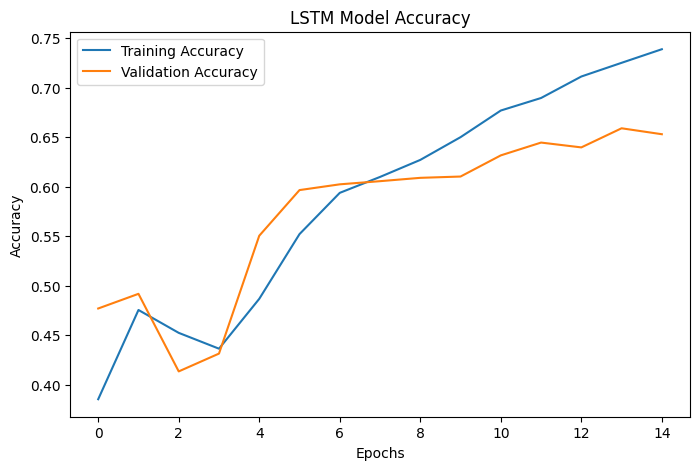

In [24]:
# Plot Training and Validation Accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('LSTM Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot Training and Validation Loss

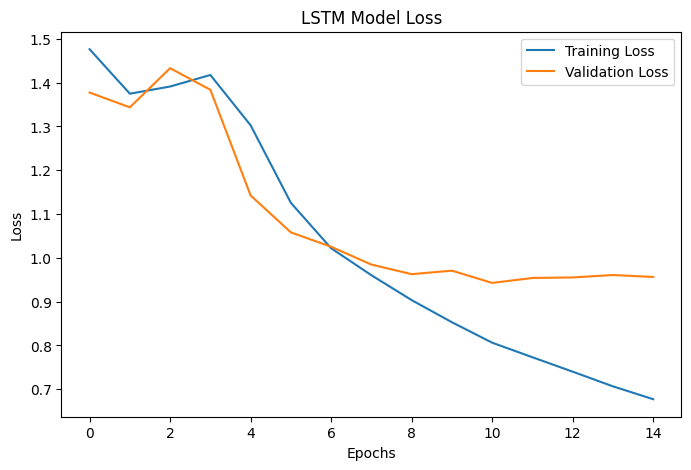

In [25]:
# Plot Training and Validation Loss
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('LSTM Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Evaluate the Model on Test Data

In [26]:
# Evaluate LSTM Model
test_loss, test_accuracy = model.evaluate(
    X_test_padded,
    y_test
)

# Display Test Results
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

209/209 ━━━━━━━━━━━━━━━━━━━━ 13s 60ms/step - accuracy: 0.6379 - loss: 0.9889
Test Loss: 0.9889231324195862
Test Accuracy: 0.6379310488700867


# Generate Classification Report

In [27]:
# Import Evaluation Metrics
from sklearn.metrics import classification_report

# Predict Test Data
y_pred_prob = model.predict(X_test_padded)

# Convert Probabilities into Class Labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Generate Classification Report
print(classification_report(
    y_test,
    y_pred,
    target_names=['1 Star', '2 Stars', '3 Stars', '4 Stars', '5 Stars']
))

209/209 ━━━━━━━━━━━━━━━━━━━━ 13s 61ms/step
              precision    recall  f1-score   support

      1 Star       0.77      0.79      0.78      1886
     2 Stars       0.36      0.37      0.37       617
     3 Stars       0.50      0.43      0.46       962
     4 Stars       0.48      0.53      0.50      1156
     5 Stars       0.76      0.73      0.74      2049

    accuracy                           0.64      6670
   macro avg       0.57      0.57      0.57      6670
weighted avg       0.64      0.64      0.64      6670



# Plot Confusion Matrix

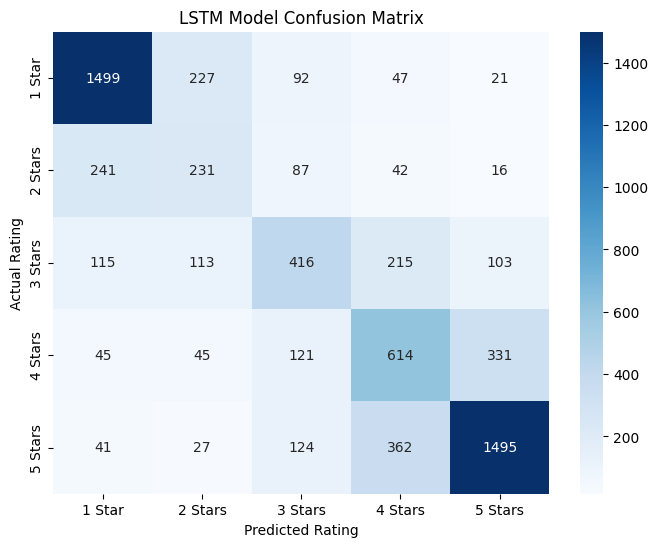

In [28]:
# Import Confusion Matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Calculate Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Plot Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['1 Star', '2 Stars', '3 Stars', '4 Stars', '5 Stars'],
    yticklabels=['1 Star', '2 Stars', '3 Stars', '4 Stars', '5 Stars']
)

plt.title('LSTM Model Confusion Matrix')
plt.xlabel('Predicted Rating')
plt.ylabel('Actual Rating')
plt.show()

In [29]:
# Install Optuna
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


# Define the Optuna Objective Function

In [33]:
# Import Required Libraries
import optuna
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

# Define Objective Function
def objective(trial):

    # Clear Previous Model
    tf.keras.backend.clear_session()

    # Select Hyperparameters
    lstm_units = trial.suggest_categorical('lstm_units', [32, 64, 128])
    dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.5)
    recurrent_dropout = 0.0
    learning_rate = trial.suggest_float('learning_rate', 0.0001, 0.01, log=True)
    batch_size = trial.suggest_categorical('batch_size', [32, 64, 128])

    # Build LSTM Model
    trial_model = Sequential()

    trial_model.add(tf.keras.layers.Input(shape=(maxlen,)))

    trial_model.add(Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=True
    ))

    trial_model.add(LSTM(
        lstm_units,
        dropout=dropout_rate,
        recurrent_dropout=recurrent_dropout
    ))

    trial_model.add(Dense(5, activation='softmax'))

    # Compile Model
    trial_model.compile(
        loss='sparse_categorical_crossentropy',
        optimizer=Adam(learning_rate=learning_rate),
        metrics=['accuracy']
    )

    # Early Stopping
    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=2,
        restore_best_weights=True
    )

    # Train Model
    history = trial_model.fit(
        X_train_padded,
        y_train,
        epochs=15,
        batch_size=batch_size,
        validation_split=0.2,
        callbacks=[early_stop],
        verbose=0
    )

    # Return Best Validation Accuracy
    return max(history.history['val_accuracy'])

# Optuna Study

In [34]:
# Create New Optuna Study
study_fast = optuna.create_study(direction='maximize')

# Run Hyperparameter Optimization
study_fast.optimize(objective, n_trials=10)

# Display Best Results
print("Best Validation Accuracy:", study_fast.best_value)
print("Best Hyperparameters:", study_fast.best_params)

[I 2026-11-26 13:41:37,669] A new study created in memory with name: no-name-b9a4f98f-1dff-471a-a504-666af64714d7
[I 2026-11-26 13:41:59,348] Trial 0 finished with value: 0.683845579624176 and parameters: {'lstm_units': 64, 'dropout_rate': 0.16385057315483265, 'learning_rate': 0.0020142690333538665, 'batch_size': 128}. Best is trial 0 with value: 0.683845579624176.
[I 2026-11-26 13:42:13,541] Trial 1 finished with value: 0.6591079235076904 and parameters: {'lstm_units': 32, 'dropout_rate': 0.3745919791001664, 'learning_rate': 0.004705293803498799, 'batch_size': 128}. Best is trial 0 with value: 0.683845579624176.
[I 2026-11-26 13:42:25,385] Trial 2 finished with value: 0.5067466497421265 and parameters: {'lstm_units': 64, 'dropout_rate': 0.3323312408441156, 'learning_rate': 0.0002877990493759616, 'batch_size': 64}. Best is trial 0 with value: 0.683845579624176.
[I 2026-11-26 13:43:39,855] Trial 3 finished with value: 0.6353073716163635 and parameters: {'lstm_units': 128, 'dropout_rate'

Best Validation Accuracy: 0.683845579624176
Best Hyperparameters: {'lstm_units': 64, 'dropout_rate': 0.16385057315483265, 'learning_rate': 0.0020142690333538665, 'batch_size': 128}


# Build and Compile Tuned Model

In [35]:
# Clear Previous Model
tf.keras.backend.clear_session()

# Get Best Hyperparameters
best_params = study_fast.best_params

# Build Tuned LSTM Model
final_model = Sequential()

final_model.add(tf.keras.layers.Input(shape=(maxlen,)))

final_model.add(Embedding(
    input_dim=vocab_size,
    output_dim=embedding_dim,
    weights=[embedding_matrix],
    trainable=True
))

final_model.add(LSTM(
    best_params['lstm_units'],
    dropout=best_params['dropout_rate'],
    recurrent_dropout=0.0
))

final_model.add(Dense(5, activation='softmax'))

# Compile Model
final_model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=Adam(learning_rate=best_params['learning_rate']),
    metrics=['accuracy']
)

# Display Model Summary
final_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 80, 100)        │     1,266,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,309,065 (4.99 MB)

 Trainable params: 1,309,065 (4.99 MB)

 Non-trainable params: 0 (0.00 B)

# Train the Tuned LSTM Model

In [36]:
# Define Early Stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Train Tuned LSTM Model
history_tuned = final_model.fit(
    X_train_padded,
    y_train,
    epochs=15,
    batch_size=best_params['batch_size'],
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/15
167/167 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.3706 - loss: 1.4806 - val_accuracy: 0.4933 - val_loss: 1.3111
Epoch 2/15
167/167 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.3618 - loss: 1.5008 - val_accuracy: 0.4333 - val_loss: 1.4375
Epoch 3/15
167/167 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.5307 - loss: 1.1785 - val_accuracy: 0.5903 - val_loss: 1.0437
Epoch 4/15
167/167 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.5972 - loss: 0.9938 - val_accuracy: 0.6063 - val_loss: 0.9633
Epoch 5/15
167/167 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.6412 - loss: 0.8835 - val_accuracy: 0.6488 - val_loss: 0.9151
Epoch 6/15
167/167 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.6895 - loss: 0.7875 - val_accuracy: 0.6544 - val_loss: 0.8921
Epoch 7/15
167/167 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.7212 - loss: 0.7165 - val_accuracy: 0.6728 - val_loss: 0.8897
Epoch 8/15
167/167 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.7545 - loss: 0.6493 - val_accu

# Evaluate the Tuned Model

In [37]:
# Evaluate Tuned LSTM Model
test_loss, test_accuracy = final_model.evaluate(
    X_test_padded,
    y_test
)

# Display Test Results
print("Tuned Model Test Loss:", test_loss)
print("Tuned Model Test Accuracy:", test_accuracy)

209/209 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.6592 - loss: 0.9166
Tuned Model Test Loss: 0.9165968298912048
Tuned Model Test Accuracy: 0.6592203974723816


# Generate Classification Report

In [38]:
# Predict Test Data
y_pred_tuned_prob = final_model.predict(X_test_padded)

# Convert Probabilities into Class Labels
y_pred_tuned = np.argmax(y_pred_tuned_prob, axis=1)

# Generate Classification Report
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=['1 Star', '2 Stars', '3 Stars', '4 Stars', '5 Stars']
))

209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
              precision    recall  f1-score   support

      1 Star       0.76      0.84      0.80      1886
     2 Stars       0.38      0.30      0.33       617
     3 Stars       0.46      0.53      0.49       962
     4 Stars       0.64      0.40      0.49      1156
     5 Stars       0.73      0.81      0.77      2049

    accuracy                           0.66      6670
   macro avg       0.59      0.57      0.58      6670
weighted avg       0.65      0.66      0.65      6670



# Plot Tuned Confusion Matrix

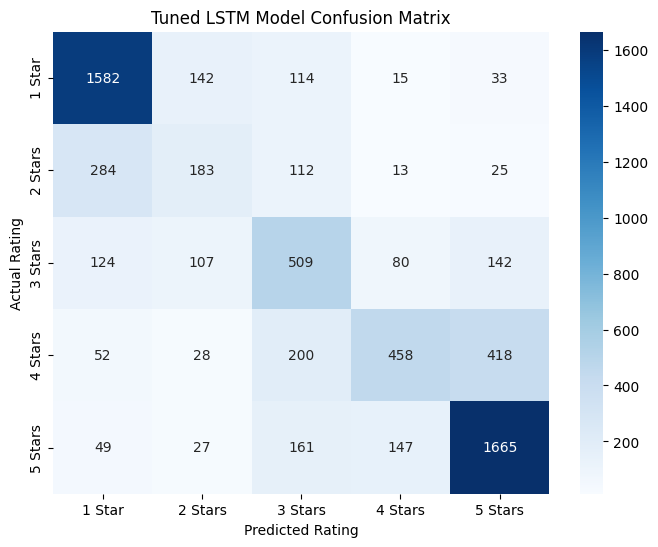

In [39]:
# Calculate Confusion Matrix
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

# Plot Confusion Matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['1 Star', '2 Stars', '3 Stars', '4 Stars', '5 Stars'],
    yticklabels=['1 Star', '2 Stars', '3 Stars', '4 Stars', '5 Stars']
)

plt.title('Tuned LSTM Model Confusion Matrix')
plt.xlabel('Predicted Rating')
plt.ylabel('Actual Rating')
plt.show()

# Save the Final Tuned LSTM Model

In [40]:
# Save Final Tuned LSTM Model
final_model.save(
    '/content/drive/MyDrive/NLP_Project/final_word2vec_lstm_model.keras'
)

print("Final Tuned LSTM Model Saved Successfully")

Final Tuned LSTM Model Saved Successfully
